# Assignment 4: Hurricane intensity classification and wind speed regression from storm records

In Assignment 3 you cleaned the IBTrACS tropical cyclone archive. Now you will model it,
using both halves of the Week 4 material on the same dataset: **regression** to predict a
continuous intensity, and **classification** to predict a storm's category.

IBTrACS is the World Meteorological Organization's official archive of global tropical
cyclone tracks, assembled from every regional forecast centre. It is real operational data,
which means it is messy: reporting practices differ by basin and have changed over time.

Answer each numbered question in the empty cell below it.


In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, mean_squared_error, r2_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, roc_auc_score)

## Load and aggregate the data

The same source and aggregation as Assignment 3, keeping only the storms with complete records,
as you did there with `dropna`. This takes a few seconds: the full archive is a large file.


In [26]:
warnings.filterwarnings('ignore', category=RuntimeWarning)

url = ('https://www.ncei.noaa.gov/data/international-best-track-archive-for-climate-'
       'stewardship-ibtracs/v04r01/access/csv/ibtracs.ALL.list.v04r01.csv')
df = pd.read_csv(url, parse_dates=['ISO_TIME'], usecols=range(12), skiprows=[1],
                 na_values=[' ', 'NOT_NAMED'], keep_default_na=False,
                 dtype={'NAME': str}, low_memory=False)

# One row per named storm, summarizing its track; drop storms with missing values.
storms = df.groupby("NAME").agg(MAX_WIND=('WMO_WIND', 'max'),
                                MIN_PRES=('WMO_PRES', 'min'),
                                MEAN_LAT=('LAT', 'mean'),
                                MEAN_LON=('LON', 'mean'),
                                BASIN=('BASIN', 'first'),
                                SEASON=('SEASON', 'first')).dropna()
del df

print(f"{len(storms)} named storms with complete records")
storms.head()

1703 named storms with complete records


,MAX_WIND,MIN_PRES,MEAN_LAT,MEAN_LON,BASIN,SEASON
NAME,,,,,,
ABAIMBA,43.0,995.0,-4.637234,63.031915,SI,2003
ABBY,120.0,895.0,20.905938,74.640937,NA,1960
ABE,85.0,945.0,22.272561,128.743293,WP,1990
ABEL:BETH,60.0,975.0,15.482927,131.466667,WP,1996
ABELA,50.0,987.0,-10.850769,65.370769,SI,2017


The **Saffir-Simpson scale** classifies storms by maximum sustained wind in knots:

| Category | Wind (kt) |
| --- | --- |
| Tropical storm | 34–63 |
| 1 | 64–82 |
| 2 | 83–95 |
| 3 | 96–112 |
| 4 | 113–136 |
| 5 | 137+ |

Categories 3 and above are **major hurricanes**.

In [42]:
storms["CATEGORY"] = np.select(
    [storms.MAX_WIND >= 137, storms.MAX_WIND >= 113, storms.MAX_WIND >= 96,
     storms.MAX_WIND >= 83,  storms.MAX_WIND >= 64],
    [5, 4, 3, 2, 1], default=0)          # 0 = tropical storm or weaker

storms["MAJOR"] = (storms.MAX_WIND >= 96).astype(int)

print(storms["CATEGORY"].value_counts().sort_index())
print(f"\nmajor hurricanes: {storms.MAJOR.sum()} of {len(storms)}")

CATEGORY
0    479
1    341
2    266
3    295
4    263
5     59
Name: count, dtype: int64

major hurricanes: 617 of 1703


## Part 1: Explore the intensity categories


1) How many storms fall in each category? Is this dataset balanced? What does that imply for the classification tasks below?

Category 0: 479
Category 1: 341
Category 2: 266
Category 3: 295
Category 4: 263
Category 5: 59

Dataset is not quite balanced, more small storms than major storms. The default threshold favors the common class. The classification task below might under identify major storms if weights are not balanced. Since missing a major storm can be life threatening to many, we are looking for better recall even if precision is not as good.

2) Plot the distribution of maximum wind speed by basin. Do all basins produce the same range of intensities?

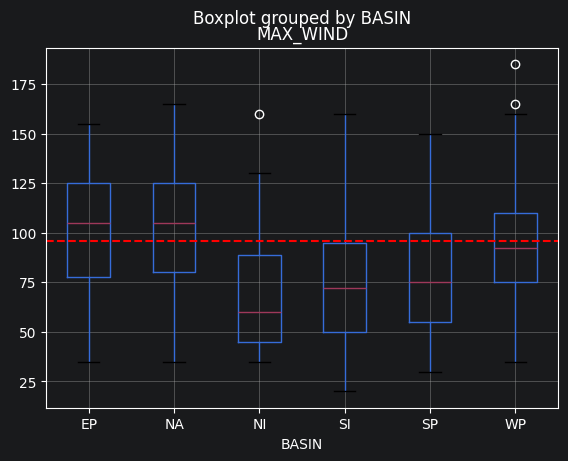

In [22]:
storms.boxplot(column='MAX_WIND', by='BASIN')
plt.axhline(96, ls='--', c='r')
plt.show()

Not all basins have the same range of intensities, EP and NA have the median over 96kt requirement for major storms. WP has some high wind speed anomalies over 150.

## Part 2: Linear regression: predicting intensity

3) Build a feature matrix from `MIN_PRES`, `MEAN_LAT`, `MEAN_LON` and `SEASON`, with
`MAX_WIND` as the target. Split into training and test sets with `random_state=0`.

In [48]:
features = ['MIN_PRES', 'MEAN_LAT', 'MEAN_LON', 'SEASON']
X = storms[features].copy()
y = storms['MAX_WIND'].copy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state=0)
print(X_train.shape, X_test.shape)

(1192, 4) (511, 4)


4) Fit a `LinearRegression` and report the RMSE and $R^2$ on the test set.

In [28]:
linear_regression = LinearRegression()
linear_regression.fit(X_train, y_train)
predicted_y_test = linear_regression.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, predicted_y_test))
print(f"RMSE on the test years: {rmse:.2f} knots")
print(f"R^2 on the test years:  {r2_score(y_test, predicted_y_test):.3f}")

RMSE on the test years: 13.04 knots
R^2 on the test years:  0.803


5) Report the fitted coefficients. Which feature dominates, and does its sign make physical sense?

In [30]:
print(linear_regression.coef_)
print('Order of Features: MIN_PRES, MEAN_LAT, MEAN_LON, SEASON')

[-0.85376126  0.126792   -0.10212812  0.02265813]
Order of Features: MIN_PRES, MEAN_LAT, MEAN_LON, SEASON


Minimum Pressure dominates - the sign is negative which means that as minimum pressure decreases, max wind speed increases. That makes sense.

6) Plot predicted against observed wind speed for the test set, with a 1:1 line. Where does the model do worst, and is that the part of the range you would most want to get right?

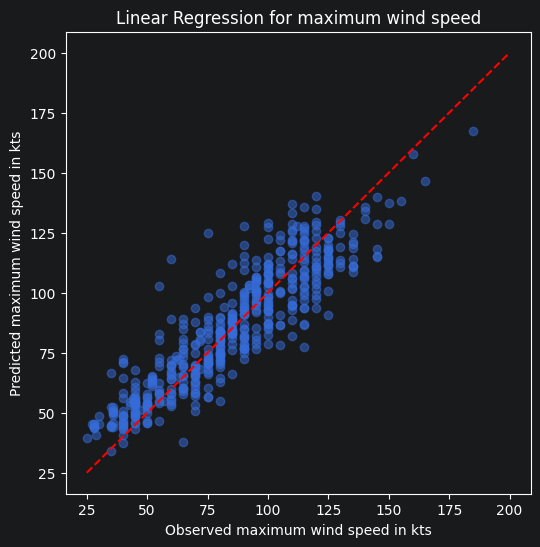

In [36]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, predicted_y_test, alpha=0.5)
limits = [25, 200]
ax.plot(limits, limits, 'r--')
ax.set_xlabel('Observed maximum wind speed in kts')
ax.set_ylabel('Predicted maximum wind speed in kts')
ax.set_title('Linear Regression for maximum wind speed')
plt.show()


The model does worst at the highest wind speeds. The model underpredicts for all data points where observed maximum wind speed is >130. That is the part of the range you would most want to get right because the highest wind speed storms are the most dangerous and it would be most dangerous to underpredict these.

7) Compare against a baseline that always predicts the mean wind speed. How much better is your model? A model that cannot beat this baseline has demonstrated nothing.

In [40]:
mean_wind_speed_training = y_train.mean()
always_predict_mean_y_test = np.full(len(y_test), mean_wind_speed_training)

print(f"RMSE for persistence = {np.sqrt(mean_squared_error(y_test, always_predict_mean_y_test)):.2f} kts")


RMSE for persistence = 29.38 kts


## Part 3: Logistic regression, will it be a major hurricane?

8) Using the same features, fit a `LogisticRegression` to predict `MAJOR`. Standardize the
features first. Use `make_pipeline(StandardScaler(), LogisticRegression())`. Why does
scaling matter here when it did not for linear regression?

In [53]:
c_train, c_test = train_test_split(storms['MAJOR'].copy(), test_size = 0.3, random_state=0)
major_clf = make_pipeline(StandardScaler(), LogisticRegression())
major_clf.fit(X_train, c_train)

major_label = major_clf.predict(X_test)


Scaling for the linear regression would have just changed the coefficients of the fit. It doesn't change the ultimate relation that it would fit to, it's just scaling the coefficients. For the Logistic Regression, different scales would lead to the model choosing prioritizing features like season and pressure with larger absolute values compared to latitude which is only in the double digits

9) Report accuracy, precision, recall and the confusion matrix on the test set.

In [64]:
print(f"logistic regression: accuracy = {accuracy_score(c_test, major_label):.3f}")
print(f"precision (when it predicts major, how often is it right): {precision_score(c_test, major_label):.3f}")
print(f"recall (of the major storms, how many did it catch): {recall_score(c_test, major_label):.3f}")

print()
print("confusion matrix (rows = not major, major; columns = predicted not major, major):")
print(confusion_matrix(c_test, major_label))


logistic regression: accuracy = 0.863
precision (when it predicts major, how often is it right): 0.786
recall (of the major storms, how many did it catch): 0.831

confusion matrix (rows = not major, major; columns = predicted not major, major):
[[294  40]
 [ 30 147]]


10) Report the ROC AUC. Then compare accuracy against a classifier that always predicts the majority class. Which metric is more informative here, and why?

In [71]:
major_prob = major_clf.predict_proba(X_test)[:, 1]
print(f"ROC AUC: {roc_auc_score(c_test, major_prob):.3f}")
print('ROC AUC of 0.943 means that the model ranks a random major hurricane above a random non-major storm 94.3% of the time. Chance would be a ROC AUC of 0.5')

label = (major_prob >= 0.5).astype(int)
always_major = np.zeros_like(c_test)

print()
print(f"Always majority class: accuracy = {accuracy_score(c_test, always_major):.3f}")
print(f"Logistic Regression: accuracy = {accuracy_score(c_test, major_label):.3f}")
print('Since ROC AUC is much further off the baseline (44.3%), while accuracy is less than half of that (20.9%), ROC AUC is more informative.')


ROC AUC: 0.943
ROC AUC of 0.943 means that the model ranks a random major hurricane above a random non-major storm 94.3% of the time. Chance would be a ROC AUC of 0.5

Always majority class: accuracy = 0.654
Logistic Regression: accuracy = 0.863
Since logistic regression is more accurate, it is more informative. 


11) Extract the predicted probabilities and plot them against minimum pressure. Where does the model sit near 0.5, and what does that region represent physically?

## Part 4: Softmax regression, the full category scale

12) Fit a multi-class logistic regression to predict `CATEGORY` (six classes). Report the
classification report and a confusion matrix.

13) Which categories does the model confuse most? Explain why in terms of how the Saffir-Simpson categories are defined, pay attention to the width of each wind-speed bin.